# Active regression coefficients: ASI and RASI

Both papers explicitly cover convex M-estimation. This implementation instantiates their **linear-regression** equations; it is not a general arbitrary-loss API. The statistical target remains the population OLS projection on V=(intercept,X1,...,X5), with beta=(1,0.8,-0.6,0,0,0). The predictor uses richer Z=(X,judges).

ASI prioritizes the focused gradient error: predicted |Y-f| multiplied by |V' Q^-1 e_j|. RASI additionally robustifies the sampling probabilities on its own burn-in. Inference uses the full regression-score sandwich, and intervals are pointwise.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

from openppi import (LinearRegression, Uncertainty, RobustDesign, get_method,
                     linear_regression_scores, select_for_labeling)
from openppi.sampling import select_burn_in
from config import Config
from dataset.regression_sim import RegressionDGP
from model.learners import SimulationLearner


## Independent prediction training and an ASI error pilot

Train the mean predictor on 400 rows. Fit the absolute-error learner on a separate 200-row pilot using predictions from that fixed model. Neither learner sees the candidate pool's labels before selection. Target covariates V are kept separate from auxiliary features Z.


In [2]:
dgp = RegressionDGP(noise='heteroskedastic')
rng = np.random.default_rng(82)
train = dgp.draw(400, rng)
pilot = dgp.draw(200, rng)
pool = dgp.draw(2000, rng)
model = SimulationLearner(Config(outcome_type='continuous', initial_prediction=1.), seed=0)
model.update(train['features'], train['y'], sample_weight=np.ones(400))
f = model.predict(pool['features'])

def error_factory():
    return RandomForestRegressor(n_estimators=40, min_samples_leaf=12, max_depth=5,
                                 random_state=0, n_jobs=1)
error_model = error_factory().fit(
    pilot['features'], np.abs(pilot['y'] - model.predict(pilot['features'])))
predicted_error = np.maximum(error_model.predict(pool['features']), 0.)
target = LinearRegression(fit_intercept=True, focus=1)
scores = linear_regression_scores(pool['x'], predicted_error, target=target)
request = select_for_labeling(f, target=target, covariates=pool['x'], scores=scores,
                             design=Uncertainty(tau=.5), budget=400, random_state=4)
record = request.with_labels(pool['y'][request.indices])
asi = get_method('ASI').inference(record, target=target, alpha=.05)
print('ASI queried labels:', len(request.indices), '+ 400 training + 200 error-pilot labels')
print('ASI coefficients:', asi.estimate)
print('Focus interval:', (asi.confidence_interval[0][1], asi.confidence_interval[1][1]))


ASI queried labels: 385 + 400 training + 200 error-pilot labels
ASI coefficients: [ 9.81925152e-01  8.19704313e-01 -5.64049569e-01 -7.57286690e-02
  1.51314530e-04  3.64602980e-02]
Focus interval: (np.float64(0.7497218187107235), np.float64(0.8896868062925891))


## RASI: its own burn-in, focused robust path and radius CV

The RASI error model uses only the burn-in, not ASI's independent pilot. All pool covariates may be used to estimate the reference Gram matrix without observing outcomes. With constraint=None, each CV fold fits its own error learner and OLS pilot on the other folds and evaluates focused coefficient scores on held-out rows. A fixed constraint can instead be supplied, as in the saved repeated experiment.


In [3]:
burn = select_burn_in(len(f), size=100, random_state=5)
b, rest = burn.indices, burn.remaining
second_budget = 400 - len(b)
design = RobustDesign.fit(
    pool['features'][b], pool['y'][b], f[b],
    target=target, covariates=pool['x'][b], reference_covariates=pool['x'],
    error_model_factory=error_factory, rho=second_budget/len(rest),
    constraint=None, candidates=(0., .01, .03, .1), folds=4, grid=51, random_state=6)
request_rasi = select_for_labeling(
    f[rest], target=target, covariates=pool['x'][rest],
    scores=design.errors(pool['features'][rest], pool['x'][rest]),
    design=design, budget=second_budget, random_state=7)
record_rasi = burn.combine(
    f, pool['y'][b], request_rasi, pool['y'][rest[request_rasi.indices]],
    covariates=pool['x'])
rasi = get_method('RASI').inference(record_rasi, target=target, alpha=.05)
print('RASI labels including burn-in:', rasi.diagnostics['audits'], '+ 400 training labels')
print('Selected radius:', rasi.diagnostics['constraint'])
print('Robust path position:', rasi.diagnostics['rho_robust'])
print('RASI coefficients:', rasi.estimate)
print('Full coefficient covariance:')
print(rasi.covariance)


RASI labels including burn-in: 420 + 400 training labels
Selected radius: 0.0
Robust path position: 0.0
RASI coefficients: [ 1.11173165  0.75304932 -0.7153953  -0.04784692 -0.0215698  -0.01079989]
Full coefficient covariance:
[[ 5.81308553e-03  5.57699586e-05 -6.87003451e-03  1.63896152e-03
   4.15934326e-04  2.05988283e-03]
 [ 5.57699586e-05  1.41740598e-03  4.09899749e-04  1.47022324e-04
   1.43921305e-04  2.54965188e-04]
 [-6.87003451e-03  4.09899749e-04  1.54659301e-02 -5.20510639e-03
  -2.17837637e-03 -5.44914813e-03]
 [ 1.63896152e-03  1.47022324e-04 -5.20510639e-03  5.90372653e-03
   2.12804047e-03  3.53604284e-03]
 [ 4.15934326e-04  1.43921305e-04 -2.17837637e-03  2.12804047e-03
   5.14401545e-03  1.92110871e-03]
 [ 2.05988283e-03  2.54965188e-04 -5.44914813e-03  3.53604284e-03
   1.92110871e-03  4.63604566e-03]]


## Repeated experiments: separate active group

Regenerate from the repository root:
```sh
python examples/simulation/regression.py --target linear --focus 1 --reps 100
```

The active group compares Uniform+IPW, ASI and RASI on the same candidate pool and fixed predictor. Nominal total query budget is 400; RASI deducts its 100 burn-in labels. ASI uses 200 extra pilot labels. Therefore equal query budgets do not imply equal total human effort. Bernoulli query counts fluctuate. The saved RASI experiment uses a fixed radius of 0.03, while the API example above demonstrates CV.


In [4]:
results_dir = Path('results_linear_regression')
summary = pd.read_csv(results_dir / 'summary.csv')
summary = summary[summary.group == 'select_labels']
print(summary[['case','method','coverage','mean_width','bias','rmse','actual_labels',
               'training_labels','pilot_labels','burn_in_labels','total_labels']].to_string(index=False))


           case      method  coverage  mean_width      bias     rmse  actual_labels  training_labels  pilot_labels  burn_in_labels  total_labels
  homoskedastic Uniform+IPW      0.93    0.138279  0.001717 0.039092         399.63            400.0           0.0             0.0        799.63
  homoskedastic         ASI      0.91    0.116934 -0.000650 0.033918         403.21            400.0         200.0             0.0       1003.21
  homoskedastic        RASI      0.96    0.130138 -0.001248 0.032235         400.80            400.0           0.0           100.0        800.80
heteroskedastic Uniform+IPW      0.96    0.167089  0.001955 0.041229         403.04            400.0           0.0             0.0        803.04
heteroskedastic         ASI      0.97    0.138504 -0.005560 0.033802         398.92            400.0         200.0             0.0        998.92
heteroskedastic        RASI      0.96    0.154084 -0.000177 0.041453         401.57            400.0           0.0           100.0

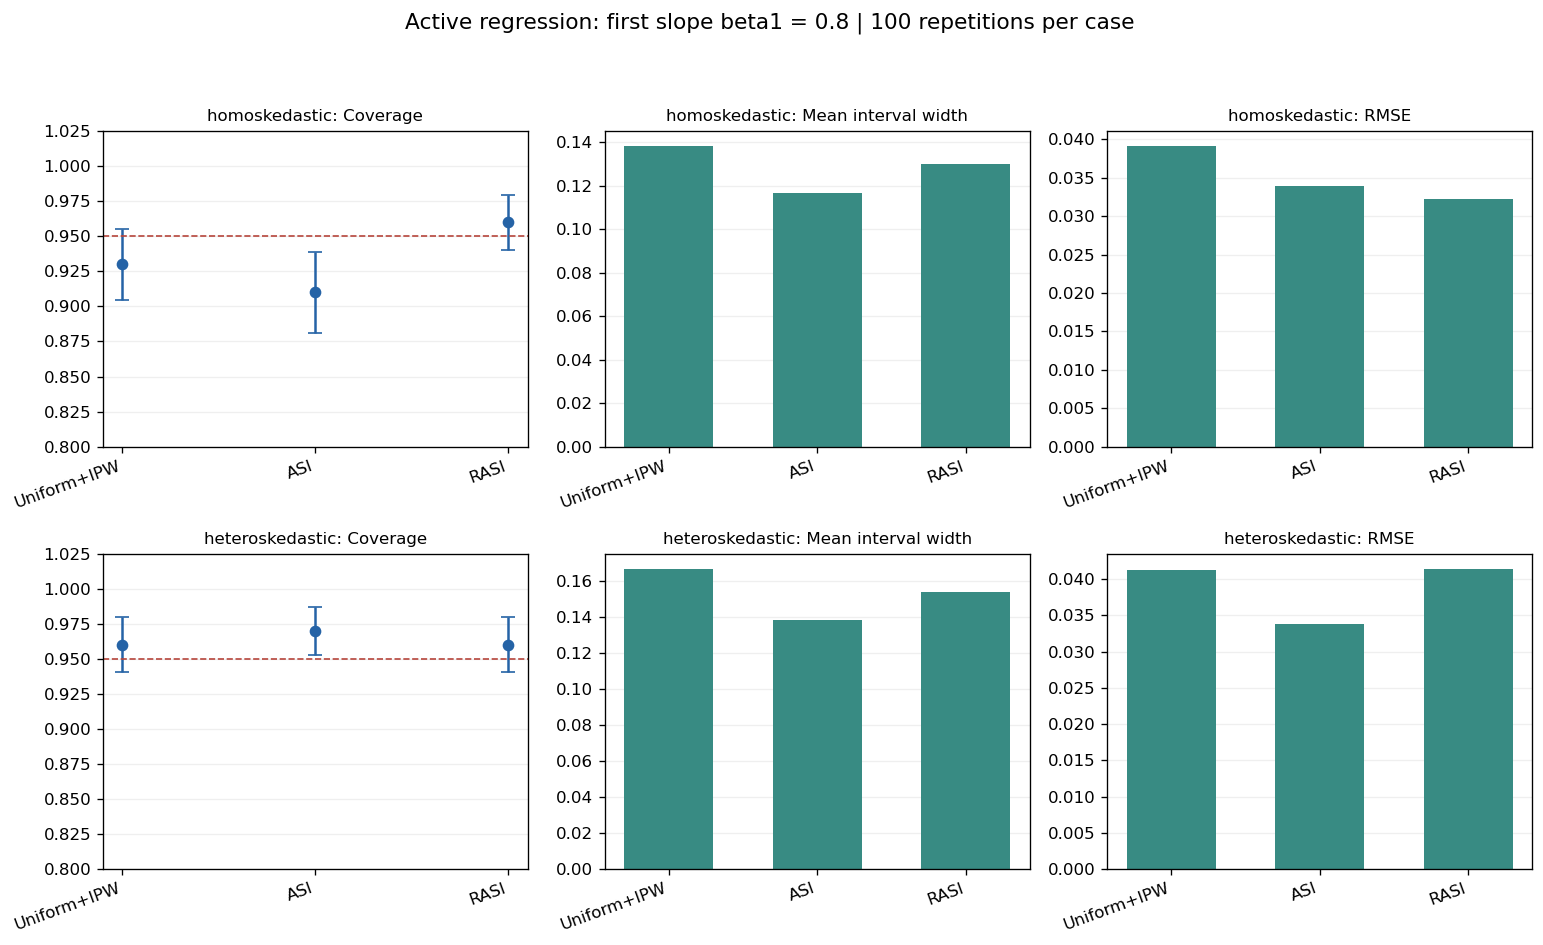

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row, noise in enumerate(('homoskedastic', 'heteroskedastic')):
    subset = summary[summary.case == noise]
    x = np.arange(len(subset))
    for col, (metric, title) in enumerate([('coverage','Coverage'), ('mean_width','Mean interval width'), ('rmse','RMSE')]):
        ax = axes[row, col]
        if metric == 'coverage':
            ax.errorbar(x, subset.coverage, yerr=subset.coverage_mc_se, fmt='o', capsize=4, color='#2563a6')
            ax.axhline(.95, linestyle='--', color='#b6453b', linewidth=1)
            ax.set_ylim(.8, 1.025)
        else:
            ax.bar(x, subset[metric], color='#388b83', width=.6)
            ax.set_ylim(bottom=0)
        ax.set_xticks(x, subset.method, rotation=20, ha='right')
        ax.set_title(f'{noise}: {title}', fontsize=10)
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
fig.suptitle('Active regression: first slope beta1 = 0.8 | 100 repetitions per case', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .94))
fig.savefig(results_dir / 'active_focus_coefficient.png', dpi=150, bbox_inches='tight')
plt.show()


Error bars show one Monte Carlo standard error. Finite-sample coverage can depart from 0.95; narrower intervals alone do not demonstrate superior inference. RASI's asymptotic comparison with uniform sampling requires its path-selection and estimation conditions, and does not guarantee that a fixed estimated robust rule wins in every 100-repetition experiment.

The original mean methods and binary score rules remain available. BAI/cube regression, FTRL regression, logistic targets, generic loss callbacks and sequential active regression updates are not enabled by this addition. Both ASI and RASI regressions solve the batch squared-loss estimating equation on the full pool with inverse-propensity pseudo-responses, not OLS on selected labels alone.
